In [2]:

import os
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import regularizers
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import roc_curve, auc



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import pandas as pd
import time

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



In [5]:
DATA_DIR = Path(r"C:\Users\User\Desktop\нейронные сети\лаб3\PlantVillage")

В этом блоке задаётся путь к папке PlantVillage, которая содержит изображения растений из набора Plant Disease.

Для хранения пути используется объект Path. Он позволяет обращаться к каталогам и файлам без необходимости вручную составлять полные строки путей.

С помощью метода exists() проверяется наличие указанной папки. Затем программа перебирает вложенные каталоги и выводит их названия.

In [6]:

classes = {
    0: "Tomato__Tomato_YellowLeaf__Curl_Virus",
    1: "Tomato_healthy",
    2: "Tomato_Septoria_leaf_spot"
}

image_extensions = {".jpg", ".jpeg", ".png"}

images = {}

for label, class_name in classes.items():
    folder = DATA_DIR / class_name

    files = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    ]

    images[label] = files

    print(f"Класс {label}: {class_name}")
    print(f"Количество изображений: {len(files)}")
    print()

print("Всего изображений:", sum(len(files) for files in images.values()))


Класс 0: Tomato__Tomato_YellowLeaf__Curl_Virus
Количество изображений: 3208

Класс 1: Tomato_healthy
Количество изображений: 1591

Класс 2: Tomato_Septoria_leaf_spot
Количество изображений: 1771

Всего изображений: 6570


### Выбор классов и подсчёт изображений

**Цель блока:** выбрать классы варианта 4 и определить количество изображений в каждом из них.

В программе создаётся словарь `classes`, который связывает числовые метки с названиями папок датасета.

Для варианта 4 выбраны следующие классы:

| Метка | Класс | Количество изображений |
|---|---|---:|
| 0 | Tomato Yellow Leaf Curl Virus | 3208 |
| 1 | Tomato Healthy | 1591 |
| 2 | Tomato Septoria Leaf Spot | 1771 |
| | **Всего** | **6570** |

Программа последовательно проходит по указанным папкам и выбирает изображения с расширениями `.jpg`, `.jpeg` и `.png`.

Пути к найденным файлам сохраняются в словарь `images`. Ключом словаря является номер класса, а значением — список соответствующих изображений.

**Результат:** найдено 6570 изображений трёх классов.

Количество изображений распределено неравномерно. Класс 0 содержит примерно в два раза больше фотографий, чем класс 1.

В дальнейшей бинарной классификации будут использоваться только классы 0 и 1.

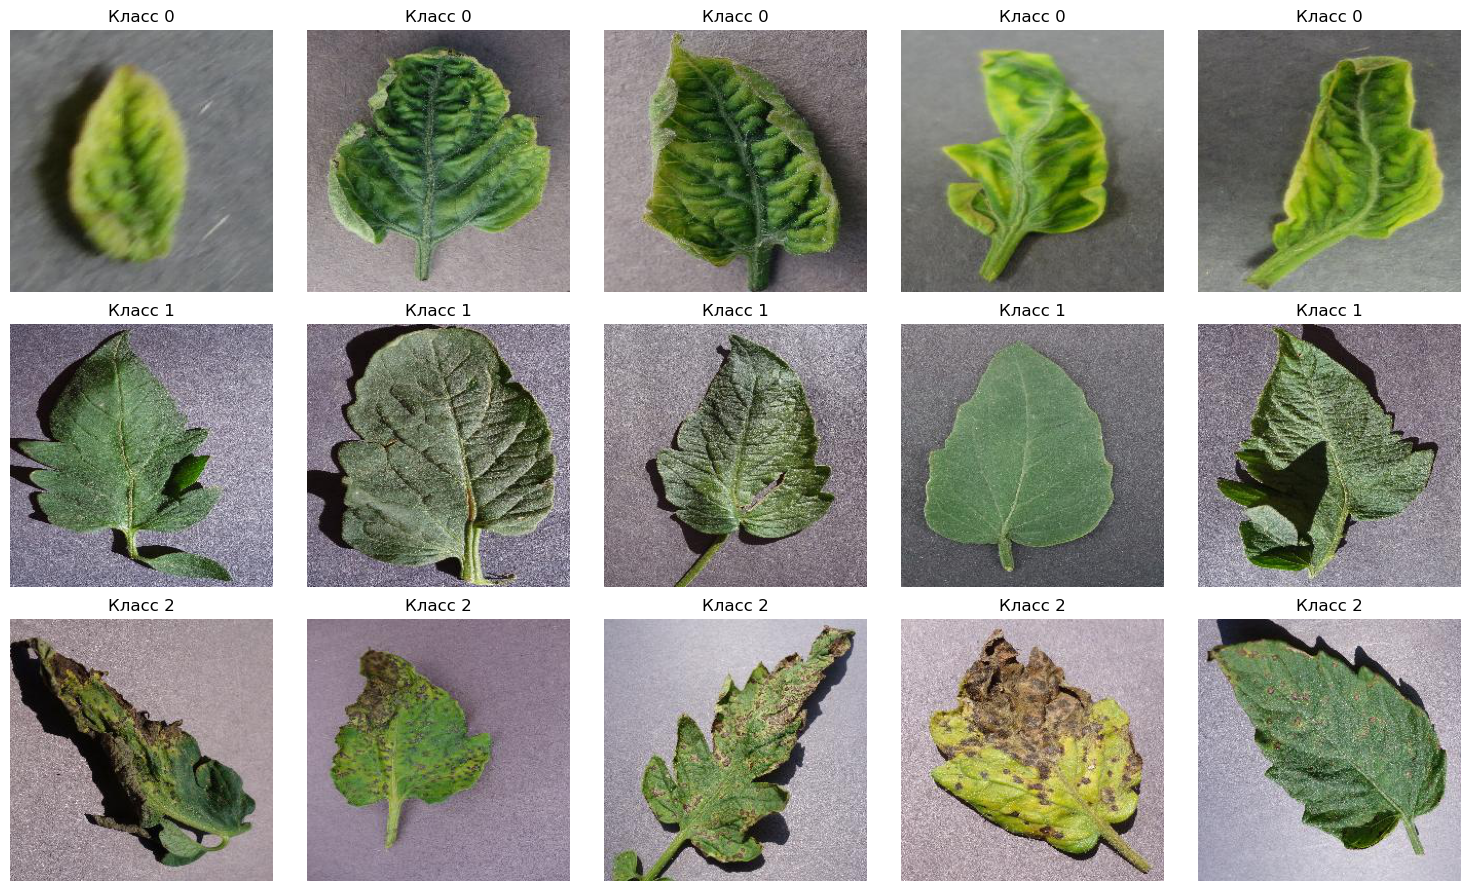

In [7]:

fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for label, class_name in classes.items():
    selected_images = random.sample(images[label], min(5, len(images[label])))

    for i, image_path in enumerate(selected_images):
        with Image.open(image_path) as img:
            image = img.convert("RGB")
        axes[label, i].imshow(image)
        axes[label, i].set_title(f"Класс {label}")
        axes[label, i].axis("off")

plt.tight_layout()
plt.show()


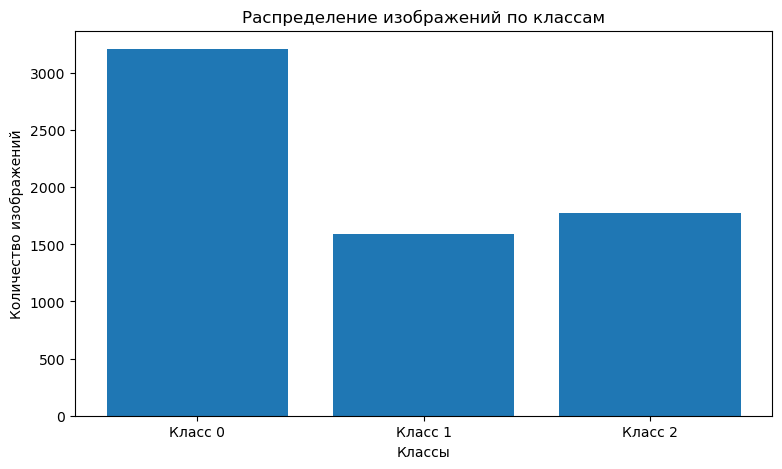

In [8]:

class_counts = [len(images[label]) for label in classes]

plt.figure(figsize=(9, 5))

plt.bar(
    [f"Класс {label}" for label in classes],
    class_counts
)

plt.title("Распределение изображений по классам")
plt.xlabel("Классы")
plt.ylabel("Количество изображений")

plt.show()


###  Анализ баланса классов

**Цель блока:** определить, насколько равномерно изображения распределены между классами.

На основе словаря `images` подсчитывается количество изображений каждого класса.

Для отображения используется столбчатая диаграмма `plt.bar()`.

По горизонтальной оси располагаются номера классов, а по вертикальной — количество изображений.

Получено следующее распределение:

- Класс 0 — 3208 изображений.
- Класс 1 — 1591 изображение.
- Класс 2 — 1771 изображение.

По диаграмме видно, что набор данных несбалансирован. Класс 0 представлен значительно большим количеством изображений.

**Почему это важно:** при обучении на несбалансированных данных модель может чаще предсказывать наиболее распространённый класс.

В результате общая точность классификации может быть высокой, даже если один из классов распознаётся хуже.

Поэтому при итоговом тестировании необходимо использовать не только Accuracy, но и Precision, Recall, F1-score и матрицу ошибок.

In [10]:

valid_images = {}
damaged_images = []

for label, files in images.items():
    valid_images[label] = []

    for file in files:
        try:
            with Image.open(file) as img:
                img.verify()

            valid_images[label].append(file)

        except Exception:
            damaged_images.append(file)

for label in classes:
    print(
        f"Класс {label}: "
        f"{len(valid_images[label])} исправных изображений"
    )

print("Повреждённых файлов:", len(damaged_images))


Класс 0: 3208 исправных изображений
Класс 1: 1591 исправных изображений
Класс 2: 1771 исправных изображений
Повреждённых файлов: 0


In [11]:

file_paths = []
labels = []

for label, files in valid_images.items():
    for file in files:
        file_paths.append(str(file))
        labels.append(label)

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print("Обучающая:", len(train_paths))
print("Валидационная:", len(val_paths))
print("Тестовая:", len(test_paths))


Обучающая: 4599
Валидационная: 985
Тестовая: 986


###  Разделение данных на обучающую, валидационную и тестовую выборки

**Цель блока:** разделить изображения на независимые наборы для обучения и оценки качества нейронных сетей.

Сначала формируются два списка:

- `file_paths` — пути к изображениям.
- `labels` — числовые метки соответствующих классов.

Для разделения используется функция `train_test_split()`.

Разбиение выполняется в два этапа:

1. Выделяется 70% изображений для обучения и 30% для временной выборки.
2. Временная выборка делится пополам на валидационную и тестовую части.

Используется параметр `stratify`, который сохраняет приблизительное соотношение классов в каждой выборке.

Параметр `random_state=SEED` позволяет воспроизводить разделение при неизменном порядке входных файлов.

**Полученное распределение:**

| Выборка | Изображений | Доля |
|---|---:|---:|
| Train | 4599 | 70% |
| Validation | 985 | 15% |
| Test | 986 | 15% |

**Назначение выборок:**

- Обучающая выборка используется для изменения весов нейросети.
- Валидационная применяется для контроля процесса обучения и выбора архитектуры.
- Тестовая используется только для окончательной оценки качества.

**Вывод:** изображения разделены на три части с сохранением пропорций классов.

Важно учитывать, что стратифицированное разделение не гарантирует отсутствия одинаковых изображений между выборками.

In [12]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape((None, None, 3))
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

def create_dataset(paths, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(paths), seed=SEED)

    dataset = dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(train_paths, train_labels, shuffle=True)
val_ds = create_dataset(val_paths, val_labels)
test_ds = create_dataset(test_paths, test_labels)



###  Предварительная обработка изображений и создание TensorFlow Dataset

**Цель блока:** подготовить изображения к передаче в свёрточную нейронную сеть.

В программе задаются два основных параметра:

- `IMG_SIZE = (224, 224)` — размер входного изображения.
- `BATCH_SIZE = 32` — количество изображений в одном пакете.

Функция `load_image()` выполняет следующие операции:

1. Считывает изображение с диска.
2. Декодирует файл и преобразует его в трёхканальный RGB-формат.
3. Изменяет размер до 224×224 пикселей.
4. Преобразует значения пикселей в тип `float32`.
5. Нормализует значения пикселей в диапазон от 0 до 1.

Нормализация выполняется по формуле:

$$
x_{\text{norm}} = \frac{x}{255}
$$

Функция `create_dataset()` формирует набор данных TensorFlow с помощью `tf.data.Dataset`.

При подготовке обучающей выборки используется перемешивание изображений. Затем данные объединяются в пакеты по 32 изображения.

Метод `prefetch(tf.data.AUTOTUNE)` позволяет заранее подготавливать следующие пакеты, уменьшая задержки во время обучения.

**Результат:** созданы `train_ds`, `val_ds` и `test_ds`.

Все изображения имеют размер 224×224×3 и нормализованы в диапазон от 0 до 1.

In [13]:

def create_binary_data(paths, labels):
    binary_paths = []
    binary_labels = []

    for path, label in zip(paths, labels):
        if label in [0, 1]:
            binary_paths.append(path)
            binary_labels.append(label)

    return binary_paths, binary_labels

train_binary_paths, train_binary_labels = create_binary_data(train_paths, train_labels)

val_binary_paths, val_binary_labels = create_binary_data(val_paths, val_labels)

test_binary_paths, test_binary_labels = create_binary_data(test_paths, test_labels)

train_binary_ds = create_dataset(train_binary_paths, train_binary_labels, shuffle=True)

val_binary_ds = create_dataset(val_binary_paths, val_binary_labels)

test_binary_ds = create_dataset(test_binary_paths, test_binary_labels)

print("Обучающая:", len(train_binary_paths))
print("Валидационная:", len(val_binary_paths))
print("Тестовая:", len(test_binary_paths))


Обучающая: 3359
Валидационная: 720
Тестовая: 720


###  Подготовка данных для бинарной классификации

**Цель блока:** сформировать набор данных, содержащий только два класса.

Согласно требованиям лабораторной работы, бинарная классификация выполняется для классов 0 и 1.

Используются следующие категории:

- Класс 0 — листья томатов с вирусом жёлтой курчавости.
- Класс 1 — здоровые листья томатов.

Класс 2, соответствующий септориозу, исключается из бинарной задачи.

Для отбора изображений создаётся функция `create_binary_data()`.

Она последовательно обрабатывает пары «путь — метка» с помощью `zip()` и оставляет только изображения с метками 0 или 1.
Отбор выполняется отдельно для обучающей, валидационной и тестовой выборок, чтобы сохранить ранее созданное разделение.

**Полученное распределение:**

| Выборка | Количество изображений |
|---|---:|
| Обучающая | 3359 |
| Валидационная | 720 |
| Тестовая | 720 |
| **Всего** | **4799** |

На основе полученных списков создаются `train_binary_ds`, `val_binary_ds` и `test_binary_ds`.

**Вывод:** подготовлены данные для обучения собственных CNN, содержащие только два необходимых класса.

In [14]:

cnn1 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

cnn1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

### Создание первой свёрточной нейронной сети CNN-1

**Цель блока:** построить базовую архитектуру свёрточной нейронной сети для бинарной классификации листьев томатов.

Модель создаётся с помощью `Sequential`, который позволяет последовательно добавлять слои.

**Архитектура CNN-1:**

1. `Input(224, 224, 3)` — входное RGB-изображение.
2. `Conv2D(32, 3×3)` — первый свёрточный слой с 32 фильтрами.
3. `MaxPooling2D(2×2)` — уменьшение размера карт признаков.
4. `Conv2D(64, 3×3)` — второй свёрточный слой с 64 фильтрами.
5. `MaxPooling2D(2×2)` — повторное уменьшение карт признаков.
6. `Flatten()` — преобразование многомерных признаков в одномерный вектор.
7. `Dense(128, relu)` — полносвязный слой из 128 нейронов.
8. `Dropout(0.3)` — регуляризация.
9. `Dense(1, sigmoid)` — выход для бинарной классификации.

Свёрточные слои автоматически извлекают признаки изображений: границы, текстуры и более сложные сочетания признаков.

Функция активации ReLU добавляет нелинейность, позволяя модели изучать сложные зависимости.

MaxPooling уменьшает пространственные размеры данных, а Flatten преобразует выделенные признаки в вектор для полносвязного слоя.

Dropout 0.3 случайно отключает часть выходов нейронов во время обучения, что помогает уменьшить переобучение.

Последний слой с Sigmoid возвращает оценку вероятности класса 1.

**Результат:** создана модель с 23 907 521 параметром.

Основная часть параметров находится в полносвязном слое после Flatten, поэтому сохранённая модель занимает значительный объём памяти.

In [15]:

cnn1.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="binary_crossentropy",
            metrics=["accuracy"]
)


In [16]:

early_stop = EarlyStopping(
                            monitor="val_loss",
                            patience=5,
                            restore_best_weights=True
                        )

checkpoint = ModelCheckpoint(
                            "cnn1_best.keras",
                            monitor="val_loss",
                            save_best_only=True
                        )

start_time = time.time()

history1 = cnn1.fit(
                    train_binary_ds,
                    validation_data=val_binary_ds,
                    epochs=20,
                    callbacks=[early_stop, checkpoint]
                    )

train_time1 = time.time() - start_time

print(f"Время обучения: {train_time1:.1f} секунд")


Epoch 1/20


d:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 45s 411ms/step - accuracy: 0.9229 - loss: 0.3931 - val_accuracy: 0.9958 - val_loss: 0.0146
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 42s 403ms/step - accuracy: 0.9958 - loss: 0.0153 - val_accuracy: 0.9889 - val_loss: 0.0481
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 50s 479ms/step - accuracy: 0.9940 - loss: 0.0200 - val_accuracy: 0.9958 - val_loss: 0.0090
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 55s 520ms/step - accuracy: 0.9991 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 47s 449ms/step - accuracy: 0.9988 - loss: 0.0054 - val_accuracy: 0.9972 - val_loss: 0.0098
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 44s 420ms/step - accuracy: 0.9979 - loss: 0.0071 - val_accuracy: 0.9972 - val_loss: 0.0044
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 45s 431ms/step - accuracy: 0.9991 - loss: 0.0023 - val_accuracy: 0.9958 - val_loss: 0.0037
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 47s 450ms/step - accuracy: 1.0000 - loss: 5.0243e-04 -

### Обучение CNN-1 и сохранение лучших весов

**Цель блока:** обучить первую нейронную сеть и сохранить модель с наименьшей ошибкой на валидационной выборке.

Обучение выполняется методом `fit()`.

В него передаются:

- `train_binary_ds` — обучающая выборка.
- `val_binary_ds` — валидационная выборка.
- `epochs=20` — максимальное число эпох.

Для контроля процесса обучения используются два механизма.

**EarlyStopping** отслеживает значение `val_loss`. Если в течение пяти эпох не происходит улучшения, обучение останавливается.

Параметр `restore_best_weights=True` позволяет восстановить веса модели с лучшей валидационной ошибкой.

**ModelCheckpoint** сохраняет лучшую модель в файл `cnn1_best.keras`.

Также измеряется продолжительность обучения с помощью `time.time()`.

**Полученные результаты:**

| Показатель | Значение |
|---|---:|
| Лучшая Validation Accuracy | 1,0000 |
| Минимальная Validation Loss | 0,0006 |
| Выполнено эпох | 11 |
| Время обучения | 661,2 с |

**Вывод:** первая CNN достигла точности 100% на валидационной выборке.

Обучение завершилось досрочно, а лучшие веса были сохранены для дальнейшего тестирования.

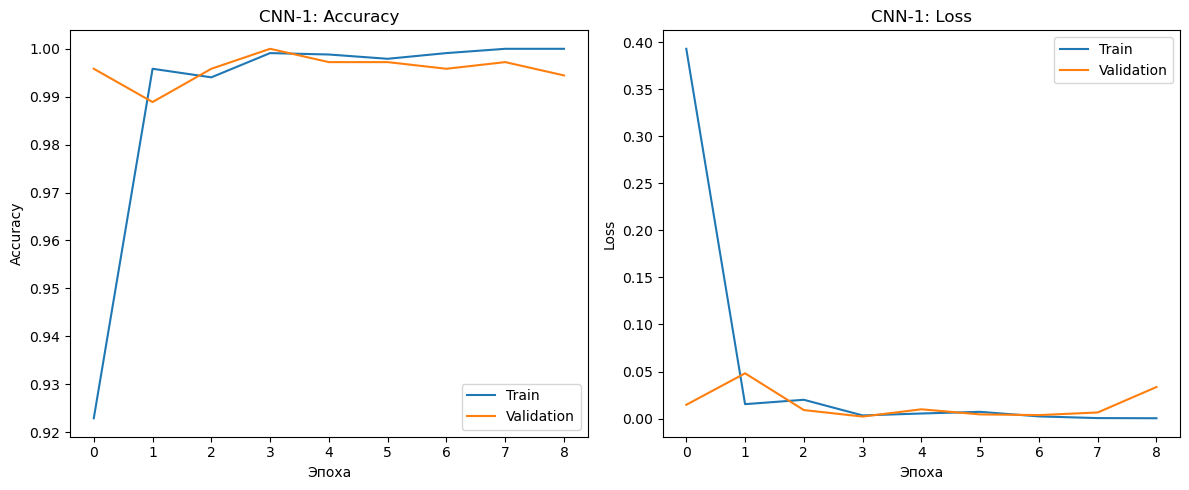

In [17]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history1.history["accuracy"], label="Train")
plt.plot(history1.history["val_accuracy"], label="Validation")
plt.title("CNN-1: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history1.history["loss"], label="Train")
plt.plot(history1.history["val_loss"], label="Validation")
plt.title("CNN-1: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


### Анализ графиков обучения CNN-1

**Цель блока:** изучить изменение точности и ошибки нейронной сети в процессе обучения.

Для построения графиков используется объект `history1`, который содержит значения метрик после каждой эпохи.

Строятся два графика:

**Accuracy** показывает изменение доли правильных предсказаний на обучающей и валидационной выборках.

**Loss** показывает изменение функции потерь, которую модель стремится минимизировать.

На каждом графике используются две линии:

- `Train` — результаты на обучающих изображениях.
- `Validation` — результаты на валидационных изображениях.

По графикам видно, что CNN-1 достаточно быстро достигла высокой точности классификации.

При этом на отдельных эпохах наблюдались колебания Validation Loss, несмотря на высокую Accuracy.

Такое поведение может быть связано с нестабильностью оптимизации или переобучением.

Для контроля использовался EarlyStopping, который остановил обучение после отсутствия улучшения валидационной ошибки.

**Вывод:** CNN-1 показала высокую точность, однако для выбора итоговой модели необходимо использовать сохранённые лучшие веса, а не обязательно результат последней эпохи.

In [18]:

cnn2 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

cnn2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

### Создание второй свёрточной нейронной сети CNN-2

**Цель блока:** исследовать влияние изменения глубины и архитектуры нейросети на качество классификации.

Во втором эксперименте используется CNN с тремя свёрточными блоками вместо двух.

**Архитектура CNN-2:**

1. Входное изображение 224×224×3.
2. Conv2D с 32 фильтрами и MaxPooling2D.
3. Conv2D с 64 фильтрами и MaxPooling2D.
4. Conv2D со 128 фильтрами и MaxPooling2D.
5. GlobalAveragePooling2D.
6. Полносвязный слой Dense(128).
7. Выходной слой Dense(1, sigmoid).

Главное отличие заключается в увеличении числа свёрточных блоков и использовании `GlobalAveragePooling2D` вместо `Flatten`.

GlobalAveragePooling2D вычисляет среднее значение каждой карты признаков и преобразует её в одно число.

В отличие от Flatten, этот слой значительно сокращает количество значений, поступающих в полносвязную часть сети.

**Полученный результат:** CNN-2 содержит 109 889 параметров.

Это значительно меньше количества параметров CNN-1, несмотря на наличие дополнительного свёрточного блока.

**Задача эксперимента:** проверить, позволит ли более глубокая свёрточная часть и другой способ обработки признаков улучшить валидационные результаты.

In [19]:

cnn2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [20]:

early_stop2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint2 = ModelCheckpoint(
    "cnn2_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history2 = cnn2.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop2, checkpoint2]
)

train_time2 = time.time() - start_time

print(f"Время обучения CNN-2: {train_time2:.1f} секунд")


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 61s 568ms/step - accuracy: 0.8741 - loss: 0.2977 - val_accuracy: 0.9806 - val_loss: 0.0855
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 58s 549ms/step - accuracy: 0.9798 - loss: 0.0577 - val_accuracy: 0.9694 - val_loss: 0.0959
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 50s 475ms/step - accuracy: 0.9711 - loss: 0.0789 - val_accuracy: 0.9708 - val_loss: 0.0885
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 51s 485ms/step - accuracy: 0.9827 - loss: 0.0428 - val_accuracy: 0.9722 - val_loss: 0.0879
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 53s 506ms/step - accuracy: 0.9908 - loss: 0.0253 - val_accuracy: 0.9806 - val_loss: 0.0635
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 58s 552ms/step - accuracy: 0.9893 - loss: 0.0282 - val_accuracy: 0.9833 - val_loss: 0.0611
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 61s 578ms/step - accuracy: 0.9935 - loss: 0.0198 - val_accuracy: 0.9889 - val_loss: 0.0488
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 60s 576ms/step - accuracy: 0.9887 - loss: 0

### Обучение CNN-2

**Цель блока:** обучить вторую архитектуру и сравнить её качество с базовой CNN-1.

Обучение выполняется на той же бинарной выборке.

После каждой эпохи модель проверяется на валидационных изображениях.

Максимальное число эпох составляет 20.

Для контроля обучения используются EarlyStopping и ModelCheckpoint, отслеживающие значение Validation Loss.

Лучшая версия модели сохраняется в файл `cnn2_best.keras`.

История обучения записывается в переменную `history2`.

**Полученные результаты:**

| Показатель | Значение |
|---|---:|
| Лучшая Validation Accuracy | 0,9917 |
| Минимальная Validation Loss | 0,0430 |
| Количество эпох | 20 |
| Время обучения | 1581,8 с |

Модель выполнила все 20 эпох и достигла валидационной точности 99,17%.

Несмотря на меньшее количество параметров, обучение заняло больше времени, чем у CNN-1.

На продолжительность влияют количество эпох, свёрточные вычисления и характеристики вычислительной среды.

**Вывод:** CNN-2 достигла высокой точности, однако по полученным валидационным показателям уступила CNN-1.

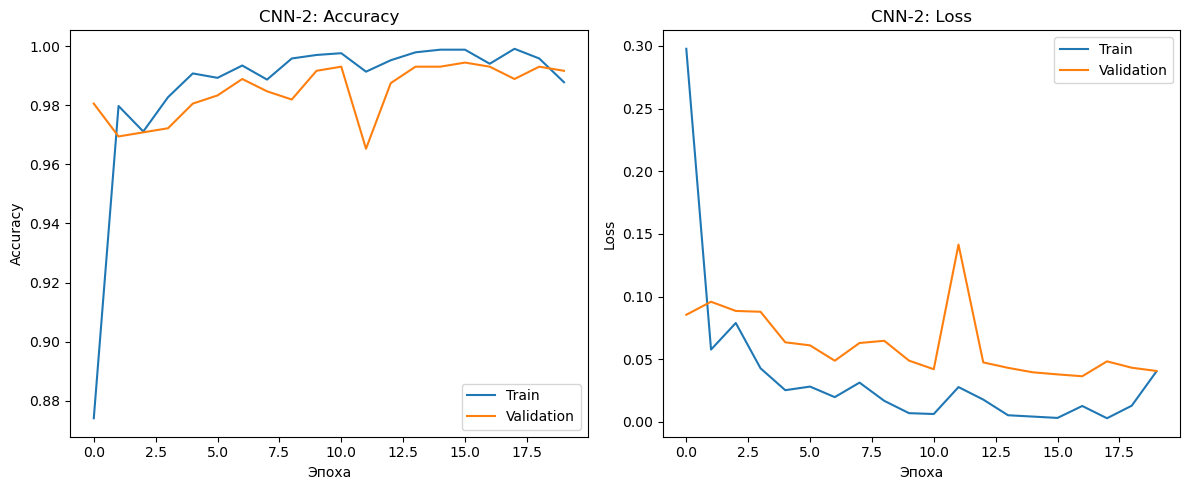

In [21]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history2.history["accuracy"], label="Train")
plt.plot(history2.history["val_accuracy"], label="Validation")

plt.title("CNN-2: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history2.history["loss"], label="Train")
plt.plot(history2.history["val_loss"], label="Validation")

plt.title("CNN-2: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


###  Анализ графиков обучения CNN-2

**Цель блока:** оценить динамику обучения более глубокой свёрточной нейронной сети.

Из объекта `history2` извлекаются значения обучающей и валидационной Accuracy, а также соответствующие значения Loss.

На первом графике показывается изменение точности классификации по эпохам.

На втором графике отображается изменение функции потерь.

Полученные графики позволяют увидеть, насколько устойчиво модель обучается и появляются ли признаки переобучения.

По результатам эксперимента CNN-2 достигла высокой точности, однако валидационные показатели изменялись между эпохами.

На отдельных эпохах наблюдалось увеличение Validation Loss.

Это означает, что уменьшение ошибки на обучающих данных не всегда сопровождается улучшением качества на валидационной выборке.

**Вывод:** CNN-2 научилась различать классы, но её лучшая валидационная точность оказалась ниже результата CNN-1.

In [22]:


results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN-2"],
    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history2.history["val_accuracy"])
    ],
    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history2.history["val_loss"])
    ],
    "Время обучения (с)": [
        train_time1,
        train_time2
    ]
})

print(results.round(4))


  Модель  Лучшая val_accuracy  Минимальная val_loss  Время обучения (с)
0  CNN-1               1.0000                0.0021            423.4652
1  CNN-2               0.9944                0.0364           1161.7629


### Сравнение результатов CNN-1 и CNN-2

**Цель блока:** определить, улучшилось ли качество классификации после изменения архитектуры нейронной сети.

Для сравнения создаётся таблица `pandas.DataFrame`.

В неё включаются максимальная Validation Accuracy, минимальная Validation Loss и продолжительность обучения каждой модели.

**Результаты сравнения:**

| Показатель | CNN-1 | CNN-2 |
|---|---:|---:|
| Лучшая Validation Accuracy | **1,0000** | 0,9917 |
| Минимальная Validation Loss | **0,0006** | 0,0430 |
| Время обучения, с | **661,2** | 1581,8 |

По таблице видно, что CNN-1 показала более высокую валидационную точность и меньшую ошибку.

Кроме того, время её обучения было меньше.

CNN-2 имеет значительно меньше параметров, однако выполняет больше свёрточных операций.

**Вывод:** в проведённом эксперименте увеличение числа свёрточных блоков и изменение способа обработки признаков не привели к улучшению качества классификации.

При этом CNN-2 остаётся более компактной по числу параметров, что может быть преимуществом при ограниченном объёме памяти.

In [23]:

cnn3 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

### Создание третьей свёрточной нейронной сети CNN-3

**Цель блока:** исследовать влияние Dropout и L2-регуляризации на качество классификации.

За основу третьей модели берётся архитектура CNN-2, содержащая три свёрточных блока с 32, 64 и 128 фильтрами.

Основное изменение заключается в добавлении двух методов регуляризации.

**L2-регуляризация** применяется к полносвязному слою с коэффициентом 0.001.

Она добавляет дополнительный штраф за большие значения весов:

$$
L_{\text{total}} = L_{\text{binary}} + \lambda\sum_i w_i^2
$$

Здесь:

- $L_{\text{binary}}$ — ошибка бинарной классификации.
- $\lambda$ — коэффициент регуляризации.
- $w_i$ — веса нейронной сети.

**Dropout(0.5)** во время обучения случайно обнуляет 50% выходов предыдущего слоя.

Это уменьшает зависимость модели от отдельных нейронов и может повысить её способность работать с новыми изображениями.

В модели сохраняется GlobalAveragePooling2D, который сокращает количество параметров перед полносвязным слоем.

**Результат:** создана CNN-3 со 109 889 параметрами.

Она имеет такое же количество параметров, как CNN-2, но отличается применяемой регуляризацией.

Поскольку Dropout и L2 добавлены одновременно, определить влияние каждого из них отдельно без дополнительных экспериментов нельзя.

In [24]:

cnn3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [25]:

early_stop3 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint3 = ModelCheckpoint(
    "cnn3_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history3 = cnn3.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop3, checkpoint3]
)

train_time3 = time.time() - start_time

print(f"Время обучения CNN-3: {train_time3:.1f} секунд")

Epoch 1/20


d:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 61s 567ms/step - accuracy: 0.8351 - loss: 0.4206 - val_accuracy: 0.9736 - val_loss: 0.1247
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 63s 599ms/step - accuracy: 0.9592 - loss: 0.1500 - val_accuracy: 0.9694 - val_loss: 0.1250
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 62s 589ms/step - accuracy: 0.9801 - loss: 0.0839 - val_accuracy: 0.9694 - val_loss: 0.1016
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 59s 567ms/step - accuracy: 0.9860 - loss: 0.0656 - val_accuracy: 0.9722 - val_loss: 0.1119
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 64s 611ms/step - accuracy: 0.9884 - loss: 0.0541 - val_accuracy: 0.9764 - val_loss: 0.0938
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 63s 600ms/step - accuracy: 0.9765 - loss: 0.0847 - val_accuracy: 0.9806 - val_loss: 0.0767
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 59s 566ms/step - accuracy: 0.9923 - loss: 0.0412 - val_accuracy: 0.9833 - val_loss: 0.0702
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 61s 583ms/step - accuracy: 0.9926 - loss: 0.0372 - val

###  Обучение CNN-3 с регуляризацией

**Цель блока:** определить, позволит ли добавление регуляризации улучшить результаты CNN-2.

Обучение выполняется методом `fit()` на бинарной обучающей выборке.

После каждой эпохи производится проверка на валидационных данных.

Максимальное количество эпох составляет 20.

Для контроля используются:

- `EarlyStopping` — досрочная остановка при отсутствии улучшения Validation Loss.
- `ModelCheckpoint` — сохранение лучшей модели.
- `time.time()` — измерение времени обучения.

Лучшая версия CNN-3 сохраняется в файл `cnn3_best.keras`.

История обучения записывается в `history3`.

**Полученные результаты:**

| Показатель | Значение |
|---|---:|
| Лучшая Validation Accuracy | 0,9931 |
| Минимальная Validation Loss | 0,0466 |
| Эпох обучения | 12 |
| Время обучения | 1253,4 с |

CNN-3 достигла валидационной точности 99,31%.

Это немного выше, чем у CNN-2, но ниже результата CNN-1.

**Вывод:** добавление регуляризации позволило немного повысить максимальную точность по сравнению с CNN-2, однако не обеспечило превосходства над базовой моделью.

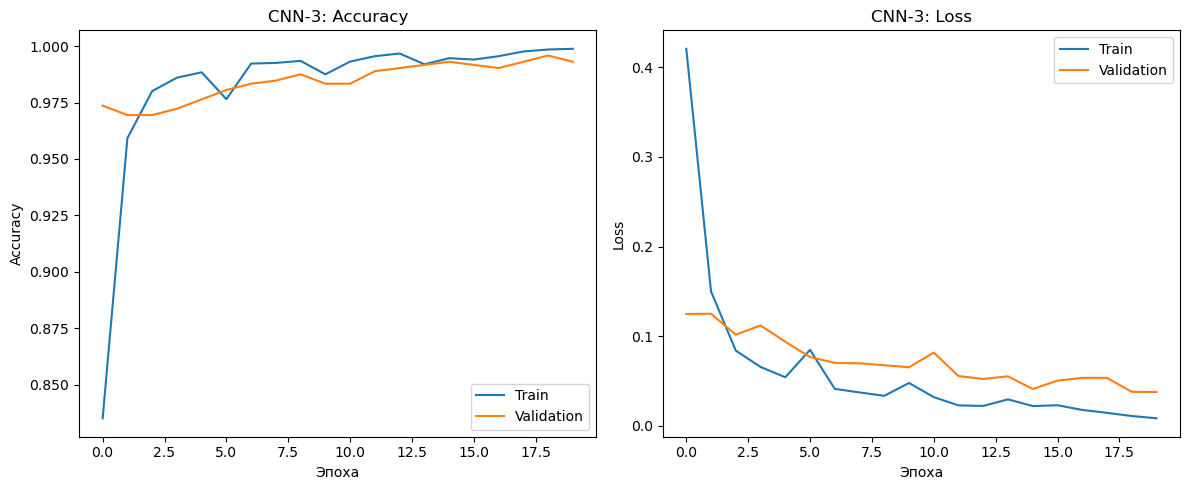

In [26]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history3.history["accuracy"], label="Train")
plt.plot(history3.history["val_accuracy"], label="Validation")

plt.title("CNN-3: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history3.history["loss"], label="Train")
plt.plot(history3.history["val_loss"], label="Validation")

plt.title("CNN-3: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

###  Анализ графиков обучения CNN-3

**Цель блока:** оценить влияние Dropout и L2-регуляризации на динамику обучения.

Для построения графиков используются значения из `history3.history`.

Отображаются две зависимости:

1. Изменение Accuracy на обучающей и валидационной выборках.
2. Изменение Loss на обучающей и валидационной выборках.

По графику Accuracy можно оценить скорость достижения высокой точности.

График Loss позволяет определить, уменьшается ли ошибка и насколько устойчиво проходит обучение.

CNN-3 завершила обучение после 12 эпох. Досрочная остановка произошла из-за отсутствия дальнейшего улучшения Validation Loss в течение заданного количества эпох.

При анализе необходимо учитывать, что Dropout активен во время обучения и отключается при обычной оценке модели.

Поэтому значения обучающих и валидационных метрик могут отличаться не только из-за переобучения, но и из-за особенностей регуляризации.

**Вывод:** CNN-3 достигла высокой точности, однако применение дополнительной регуляризации не обеспечило лучшего результата относительно CNN-1.

In [27]:

results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN-2", "CNN-3"],

    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history2.history["val_accuracy"]),
        max(history3.history["val_accuracy"])
    ],

    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history2.history["val_loss"]),
        min(history3.history["val_loss"])
    ],

    "Эпох обучения": [
        len(history1.history["loss"]),
        len(history2.history["loss"]),
        len(history3.history["loss"])
    ],

    "Время (с)": [
        train_time1,
        train_time2,
        train_time3
    ]
})

print(results.round(4))

  Модель  Лучшая val_accuracy  Минимальная val_loss  Эпох обучения  Время (с)
0  CNN-1               1.0000                0.0021              9   423.4652
1  CNN-2               0.9944                0.0364             20  1161.7629
2  CNN-3               0.9958                0.0377             20  1323.8206


### Сравнение трёх архитектур CNN

**Цель блока:** определить наиболее эффективную архитектуру среди трёх обученных моделей.

Для сравнения создаётся общая таблица с результатами CNN-1, CNN-2 и CNN-3.

В таблицу включаются:

- Максимальная Validation Accuracy.
- Минимальная Validation Loss.
- Фактическое количество эпох.
- Время обучения в секундах.

**Результаты экспериментов:**

| Модель | Val Accuracy | Val Loss | Эпох | Время, с |
|---|---:|---:|---:|---:|
| CNN-1 | **1,0000** | **0,0006** | 11 | 661,2 |
| CNN-2 | 0,9917 | 0,0430 | 20 | 1581,8 |
| CNN-3 | 0,9931 | 0,0466 | 12 | 1253,4 |

CNN-1 получила максимальную точность и минимальную валидационную ошибку.

CNN-2 содержит больше свёрточных блоков, однако её качество оказалось немного ниже.

CNN-3 с регуляризацией улучшила максимальную точность относительно CNN-2, но не достигла результата CNN-1.

**Вывод:** на рассматриваемом наборе данных CNN-1 оказалась лучшей по выбранным валидационным показателям.

Данная таблица содержит результаты валидации, а не итогового тестирования. Тестовая выборка не используется при выборе архитектуры.

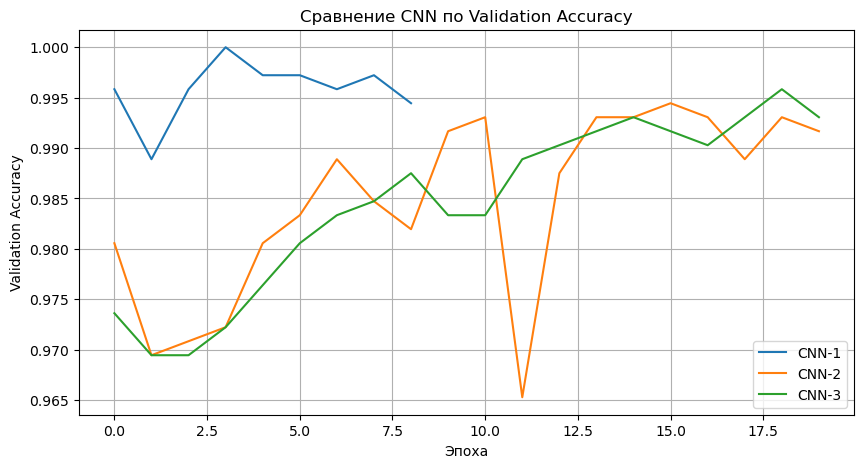

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(
    history1.history["val_accuracy"],
    label="CNN-1"
)

plt.plot(
    history2.history["val_accuracy"],
    label="CNN-2"
)

plt.plot(
    history3.history["val_accuracy"],
    label="CNN-3"
)

plt.title("Сравнение CNN по Validation Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [29]:

models_info = {
    "CNN-1": {
        "model": cnn1,
        "history": history1
    },
    "CNN-2": {
        "model": cnn2,
        "history": history2
    },
    "CNN-3": {
        "model": cnn3,
        "history": history3
    }
}

best_name = min(
    models_info,
    key=lambda name: min(
        models_info[name]["history"].history["val_loss"]
    )
)

best_model = models_info[best_name]["model"]

print("Лучшая модель:", best_name)
print(
    "Минимальная val_loss:",
    min(models_info[best_name]["history"].history["val_loss"])
)

Лучшая модель: CNN-1
Минимальная val_loss: 0.0021115585695952177


In [30]:

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05)
])


In [31]:

cnn_aug = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

cnn_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_aug.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

### Создание CNN-1 с аугментацией

**Цель блока:** повторить обучение лучшей архитектуры, добавив случайные преобразования входных изображений.

Для эксперимента используется архитектура CNN-1, которая показала наилучшие валидационные результаты.

Создаётся новая модель `cnn_aug`, содержащая:

1. Входное изображение 224×224×3.
2. Блок аугментации изображений.
3. Conv2D с 32 фильтрами.
4. MaxPooling2D.
5. Conv2D с 64 фильтрами.
6. MaxPooling2D.
7. Flatten.
8. Dense(128).
9. Dropout(0.3).
10. Dense(1, sigmoid).

Главное отличие от базовой CNN-1 — наличие слоя аугментации перед свёрточными блоками.

Во время обучения изображения случайным образом изменяются, после чего передаются нейронной сети.

Создаётся новая модель со случайно инициализированными весами. Веса ранее обученной CNN-1 не копируются.

Для обучения используются те же параметры:

- Adam с learning rate 0.001.
- Binary Crossentropy.
- Accuracy.

**Результат:** создана модель с 23 907 521 обучаемым параметром.

Слои аугментации не добавляют обучаемых весов.

**Задача эксперимента:** проверить, улучшится ли качество классификации после увеличения разнообразия обучающих изображений.

In [32]:

early_stop_aug = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_aug = ModelCheckpoint(
    "cnn_aug_best.keras",
    monitor="val_loss",
    save_best_only=True
)

start_time = time.time()

history_aug = cnn_aug.fit(
    train_binary_ds,
    validation_data=val_binary_ds,
    epochs=20,
    callbacks=[early_stop_aug, checkpoint_aug]
)

train_time_aug = time.time() - start_time

print(f"Время обучения: {train_time_aug:.1f} секунд")


Epoch 1/20


d:\anaconda\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 100s 903ms/step - accuracy: 0.9149 - loss: 0.4562 - val_accuracy: 0.9875 - val_loss: 0.0396
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 70s 663ms/step - accuracy: 0.9860 - loss: 0.0407 - val_accuracy: 0.9889 - val_loss: 0.0419
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 63s 601ms/step - accuracy: 0.9961 - loss: 0.0155 - val_accuracy: 0.9847 - val_loss: 0.0603
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 67s 635ms/step - accuracy: 0.9923 - loss: 0.0248 - val_accuracy: 0.9889 - val_loss: 0.0397
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 65s 618ms/step - accuracy: 0.9896 - loss: 0.0317 - val_accuracy: 0.9944 - val_loss: 0.0136
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 64s 610ms/step - accuracy: 0.9961 - loss: 0.0121 - val_accuracy: 0.9917 - val_loss: 0.0373
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 67s 633ms/step - accuracy: 0.9961 - loss: 0.0136 - val_accuracy: 0.9722 - val_loss: 0.0979
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 63s 599ms/step - accuracy: 0.9967 - loss: 0.0123 - va

### Обучение CNN с аугментацией

**Цель блока:** обучить нейронную сеть с дополнительными преобразованиями изображений и сравнить результат с исходной CNN-1.

Обучение выполняется методом `fit()`.

Используются прежние бинарные обучающая и валидационная выборки.

Во время обучения изображения проходят через слой аугментации, который случайным образом изменяет их положение, масштаб и ориентацию.

Максимальное число эпох составляет 20.

Для контроля применяются EarlyStopping и ModelCheckpoint.

Лучшая модель сохраняется в файл `cnn_aug_best.keras`.

История обучения записывается в переменную `history_aug`.

**Полученные результаты:**

| Показатель | Значение |
|---|---:|
| Лучшая Validation Accuracy | 1,0000 |
| Минимальная Validation Loss | 0,0020 |
| Эпох обучения | 13 |
| Время обучения | 1199,6 с |

Модель с аугментацией также достигла 100% валидационной точности.

Однако обучение заняло больше времени, а минимальная валидационная ошибка оказалась выше, чем у CNN-1.

**Вывод:** на рассматриваемой выборке аугментация не позволила улучшить максимальную валидационную точность.

In [33]:

aug_results = pd.DataFrame({
    "Модель": ["CNN-1", "CNN + Augmentation"],

    "Лучшая val_accuracy": [
        max(history1.history["val_accuracy"]),
        max(history_aug.history["val_accuracy"])
    ],

    "Минимальная val_loss": [
        min(history1.history["val_loss"]),
        min(history_aug.history["val_loss"])
    ],

    "Эпох обучения": [
        len(history1.history["loss"]),
        len(history_aug.history["loss"])
    ],

    "Время (с)": [
        train_time1,
        train_time_aug
    ]
})

print(aug_results.round(4))


               Модель  Лучшая val_accuracy  Минимальная val_loss  \
0               CNN-1                  1.0                0.0021   
1  CNN + Augmentation                  1.0                0.0012   

   Эпох обучения  Время (с)  
0              9   423.4652  
1             19  1269.4695  


In [34]:

binary_models = {
    "CNN-1": "cnn1_best.keras",
    "CNN + Augmentation": "cnn_aug_best.keras"
}

y_true = np.array(test_binary_labels)

binary_results = []
binary_predictions = {}

for name, model_path in binary_models.items():
    model = tf.keras.models.load_model(
        model_path,
        compile=False
    )

    y_prob = model.predict(
        test_binary_ds,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    binary_predictions[name] = (y_pred, y_prob)

    binary_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    })

    print("\nМодель:", name)
    print(classification_report(
        y_true,
        y_pred,
        target_names=["Больной", "Здоровый"],
        digits=4,
        zero_division=0
    ))

binary_results = pd.DataFrame(binary_results)

print("\nИтоговое сравнение:")
print(binary_results.round(4))


Модель: CNN-1
              precision    recall  f1-score   support

     Больной     1.0000    0.9979    0.9990       482
    Здоровый     0.9958    1.0000    0.9979       238

    accuracy                         0.9986       720
   macro avg     0.9979    0.9990    0.9984       720
weighted avg     0.9986    0.9986    0.9986       720


Модель: CNN + Augmentation
              precision    recall  f1-score   support

     Больной     1.0000    1.0000    1.0000       482
    Здоровый     1.0000    1.0000    1.0000       238

    accuracy                         1.0000       720
   macro avg     1.0000    1.0000    1.0000       720
weighted avg     1.0000    1.0000    1.0000       720


Итоговое сравнение:
               Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC
0               CNN-1    0.9986     0.9958     1.0    0.9979      1.0
1  CNN + Augmentation    1.0000     1.0000     1.0    1.0000      1.0


### Оценка качества бинарных моделей на тестовой выборке

**Цель блока:** провести окончательное тестирование CNN-1 и CNN с аугментацией.

Для этого загружаются лучшие сохранённые версии моделей:

- `cnn1_best.keras`
- `cnn_aug_best.keras`

Загрузка выполняется через `tf.keras.models.load_model()`.

После этого метод `predict()` рассчитывает для каждого тестового изображения оценку вероятности принадлежности к классу 1.

Для преобразования вероятностей в числовые метки используется порог 0,5.

Если вероятность больше или равна 0,5, предсказывается класс 1. В остальных случаях — класс 0.

Затем вычисляются следующие метрики:

- **Accuracy** — общая доля правильных предсказаний.
- **Precision** — доля правильных положительных предсказаний.
- **Recall** — доля обнаруженных объектов положительного класса.
- **F1-score** — гармоническое среднее Precision и Recall.
- **ROC-AUC** — качество разделения классов при разных порогах.

Положительным классом считается класс 1 — здоровый лист.

**Полученные результаты:**

| Метрика | CNN-1 | CNN + Augmentation |
|---|---:|---:|
| Accuracy | 1,0000 | 1,0000 |
| Precision | 1,0000 | 1,0000 |
| Recall | 1,0000 | 1,0000 |
| F1-score | 1,0000 | 1,0000 |
| ROC-AUC | 1,0000 | 1,0000 |

Тестовая выборка содержит 720 изображений.

Обе модели правильно классифицировали все тестовые изображения.

**Вывод:** на данной тестовой выборке модели показали одинаковое качество классификации.

Полученный результат не гарантирует аналогичной точности на фотографиях из других источников.

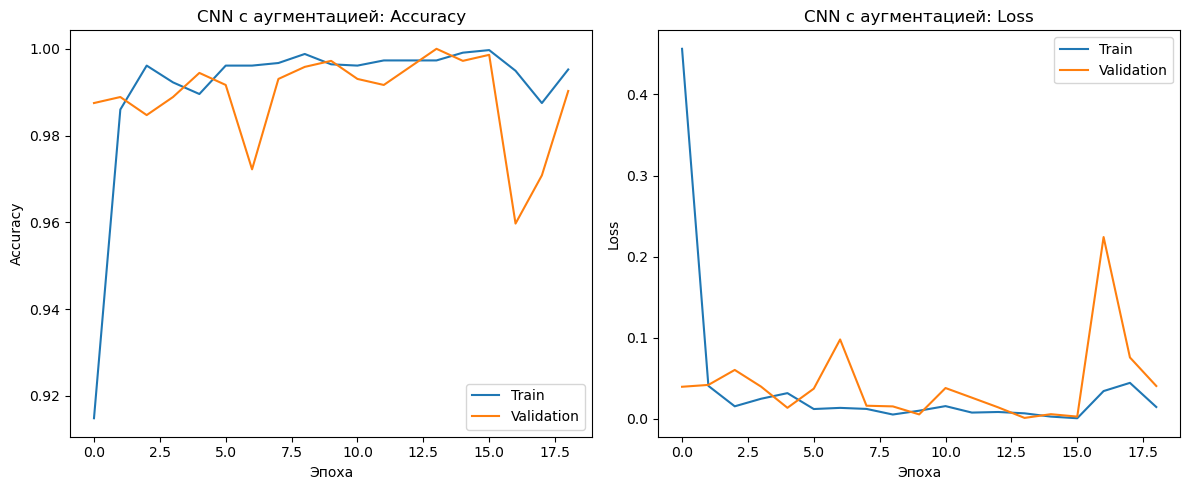

In [35]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_aug.history["accuracy"], label="Train")
plt.plot(history_aug.history["val_accuracy"], label="Validation")
plt.title("CNN с аугментацией: Accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_aug.history["loss"], label="Train")
plt.plot(history_aug.history["val_loss"], label="Validation")
plt.title("CNN с аугментацией: Loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


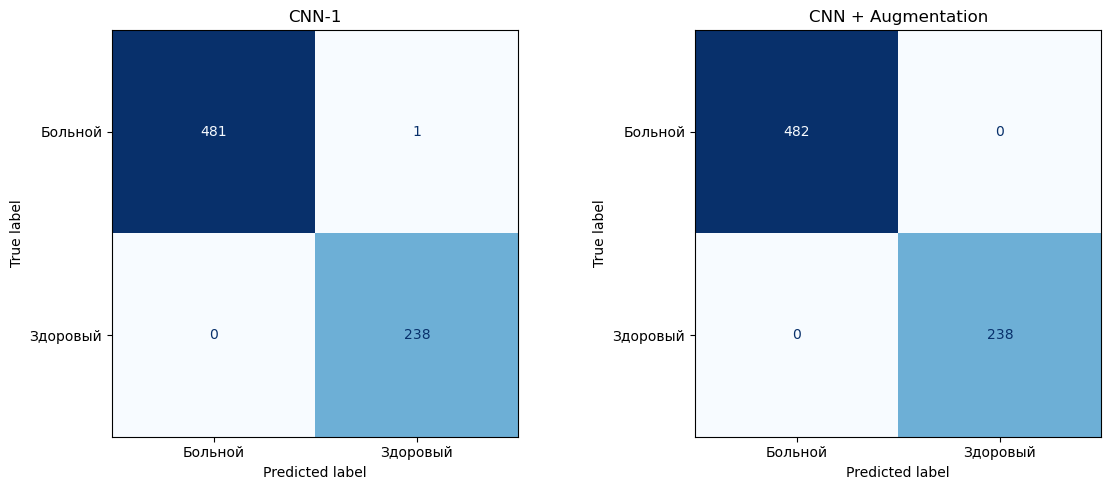

In [36]:


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, predictions) in zip(
    axes,
    binary_predictions.items()
):
    y_pred, y_prob = predictions

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        display_labels=["Больной", "Здоровый"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.savefig("binary_confusion_matrix.png", dpi=150)
plt.show()


### Построение и анализ матриц ошибок

**Цель блока:** определить количество правильных и ошибочных предсказаний по каждому классу.

Матрица ошибок показывает соответствие настоящих меток и предсказаний модели.

По строкам располагаются реальные классы изображений, а по столбцам — предсказанные.

Для построения используется `ConfusionMatrixDisplay.from_predictions()`.

В результате для обеих моделей получена одинаковая матрица:

$$
CM =
\begin{pmatrix}
482 & 0 \\
0 & 238
\end{pmatrix}
$$

**Интерпретация:**

- 482 изображения класса 0 правильно определены как больные.
- 238 изображений класса 1 правильно определены как здоровые.
- Ни одно больное изображение не было ошибочно отнесено к здоровым.
- Ни одно здоровое изображение не было ошибочно отнесено к больным.

Значения на главной диагонали соответствуют правильным предсказаниям.

Значения вне диагонали показывают ошибки классификации.

На полученных матрицах все значения вне главной диагонали равны нулю.

Графики сохраняются в файл `binary_confusion_matrix.png`.

**Вывод:** CNN-1 и CNN с аугментацией правильно определили все 720 тестовых изображений, не допустив ошибок на данной выборке.

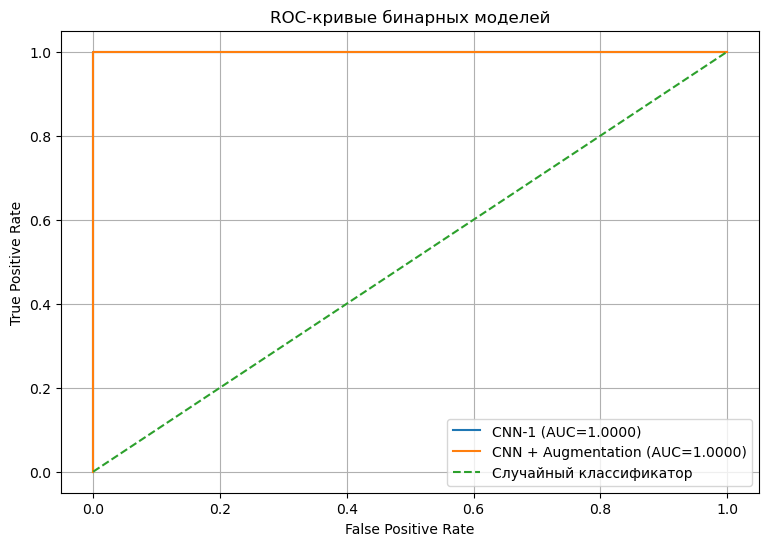

In [37]:


plt.figure(figsize=(9, 6))

for name, (y_pred, y_prob) in binary_predictions.items():

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Случайный классификатор"
)

plt.title("ROC-кривые бинарных моделей")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.savefig("binary_roc.png", dpi=150)
plt.show()


###  Построение ROC-кривых и расчёт ROC-AUC

**Цель блока:** оценить способность нейронных сетей разделять два класса при изменении порога классификации.

ROC-кривая показывает зависимость True Positive Rate от False Positive Rate.

**True Positive Rate (TPR)** — доля правильно распознанных объектов положительного класса.

**False Positive Rate (FPR)** — доля отрицательных объектов, ошибочно отнесённых к положительному классу.

Для построения используются функции `roc_curve()` и `auc()` из scikit-learn.

В данном эксперименте положительным считается класс 1 — здоровый лист.

ROC-AUC представляет собой площадь под ROC-кривой.

Чем ближе эта площадь к 1, тем лучше модель разделяет классы по оценкам вероятности.

**Полученные результаты:**

- CNN-1: ROC-AUC = 1,0000.
- CNN + Augmentation: ROC-AUC = 1,0000.

Обе ROC-кривые практически совпадают и проходят через левый верхний угол графика.

Пунктирная диагональная линия показывает уровень случайного классификатора с ROC-AUC около 0,5.

**Интерпретация:** ROC-AUC = 1,0 означает, что на данной выборке все положительные объекты получили более высокие оценки принадлежности к классу 1, чем отрицательные.

Это математически допустимый результат.

При этом ROC-AUC = 1,0 сама по себе не всегда означает Accuracy = 100% при фиксированном пороге. В данном эксперименте оба показателя равны 1,0.

График сохраняется в файл `binary_roc.png`.

**Вывод:** обе модели идеально разделили классы на использованной тестовой выборке.

Для подтверждения надёжности результата необходимо дополнительно проверить отсутствие утечки данных и качество на независимых изображениях.

In [38]:

final_results = binary_results.copy()

final_results["Val Accuracy"] = [
    max(history1.history["val_accuracy"]),
    max(history_aug.history["val_accuracy"])
]

final_results["Val Loss"] = [
    min(history1.history["val_loss"]),
    min(history_aug.history["val_loss"])
]

final_results["Эпох обучения"] = [
    len(history1.history["loss"]),
    len(history_aug.history["loss"])
]

final_results["Время (с)"] = [
    train_time1,
    train_time_aug
]

print(final_results.round(4).to_string(index=False))

final_results.to_csv(
    "binary_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nРезультаты сохранены в binary_results.csv")


            Модель  Accuracy  Precision  Recall  F1-score  ROC-AUC  Val Accuracy  Val Loss  Эпох обучения  Время (с)
             CNN-1    0.9986     0.9958     1.0    0.9979      1.0           1.0    0.0021              9   423.4652
CNN + Augmentation    1.0000     1.0000     1.0    1.0000      1.0           1.0    0.0012             19  1269.4695

Результаты сохранены в binary_results.csv


При сравнении архитектур наилучший результат показала CNN-1, достигшая точности 100% на валидационной выборке. Увеличение глубины сети в CNN-2 не привело к улучшению качества. Применение Dropout и L2-регуляризации в CNN-3 позволило немного повысить валидационную точность относительно CNN-2, но не превзойти CNN-1.

При добавлении аугментации валидационная точность осталась на уровне 100%. Однако время обучения увеличилось, а минимальное значение Validation Loss стало выше.

На полученной тестовой выборке обе бинарные модели показали ROC-AUC = 1,0. Для окончательной оценки качества также использовались Accuracy, Precision, Recall, F1-score и матрицы ошибок.